# Transfer Learning — 5A to 5C

One image-classification transfer-learning workflow with ResNet50. The image datasets must be extracted into class folders.

In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

path = "caltech-101"   # Intel: "Intel Image Classification"
                        # Fashion: "fashion mnist/train"

gen = ImageDataGenerator(preprocessing_function=preprocess_input, validation_split=0.2)

train = gen.flow_from_directory(path, target_size=(32,32),color_mode="rgb", batch_size=32,
                                class_mode="categorical", subset="training")
val = gen.flow_from_directory(path, target_size=(32,32), color_mode="rgb", batch_size=32,
                              class_mode="categorical", subset="validation")

n = train.num_classes

Found 7356 images belonging to 102 classes.
Found 1788 images belonging to 102 classes.


In [3]:
base = ResNet50(weights="imagenet", include_top=False, input_shape=(32,32,3))
base.trainable = False

model = models.Sequential([
    base, layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dense(n, activation="softmax")
])

model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
history = model.fit(train, epochs=5, validation_data=val)

print("Accuracy:", model.evaluate(val)[1])

Epoch 1/5
230/230 ━━━━━━━━━━━━━━━━━━━━ 92s 381ms/step - accuracy: 0.3831 - loss: 3.0162 - val_accuracy: 0.4323 - val_loss: 2.5388
Epoch 2/5
230/230 ━━━━━━━━━━━━━━━━━━━━ 20s 85ms/step - accuracy: 0.5574 - loss: 1.8292 - val_accuracy: 0.4726 - val_loss: 2.3969
Epoch 3/5
230/230 ━━━━━━━━━━━━━━━━━━━━ 18s 79ms/step - accuracy: 0.6815 - loss: 1.2241 - val_accuracy: 0.4922 - val_loss: 2.3366
Epoch 4/5
230/230 ━━━━━━━━━━━━━━━━━━━━ 19s 82ms/step - accuracy: 0.7826 - loss: 0.8130 - val_accuracy: 0.4815 - val_loss: 2.4643
Epoch 5/5
230/230 ━━━━━━━━━━━━━━━━━━━━ 18s 80ms/step - accuracy: 0.8598 - loss: 0.5205 - val_accuracy: 0.4905 - val_loss: 2.6601
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - accuracy: 0.4905 - loss: 2.6601
Accuracy: 0.49049216508865356


In [4]:
base.trainable = True
for layer in base.layers[:-4]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(0.00001),
              loss="categorical_crossentropy", metrics=["accuracy"])
model.fit(train, epochs=3, validation_data=val)

Epoch 1/3
230/230 ━━━━━━━━━━━━━━━━━━━━ 32s 118ms/step - accuracy: 0.9409 - loss: 0.2808 - val_accuracy: 0.4860 - val_loss: 2.6422
Epoch 2/3
230/230 ━━━━━━━━━━━━━━━━━━━━ 20s 87ms/step - accuracy: 0.9594 - loss: 0.2297 - val_accuracy: 0.4894 - val_loss: 2.6465
Epoch 3/3
230/230 ━━━━━━━━━━━━━━━━━━━━ 21s 91ms/step - accuracy: 0.9675 - loss: 0.2029 - val_accuracy: 0.4922 - val_loss: 2.6529


In [5]:
print("Accuracy:", model.evaluate(val)[1])

56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step - accuracy: 0.4922 - loss: 2.6529
Accuracy: 0.4921700358390808


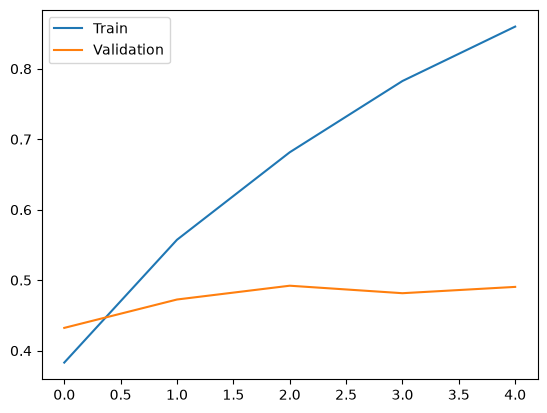

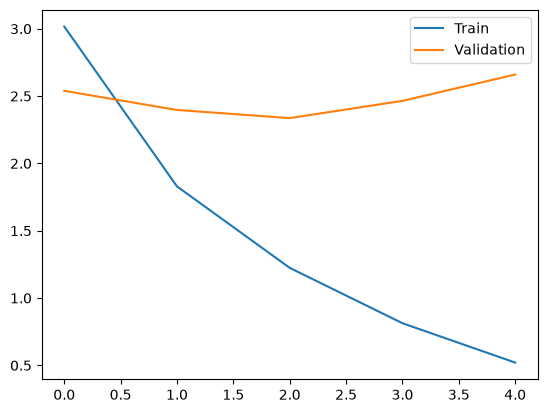

In [6]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.legend(["Train","Validation"])
plt.show()

plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.legend(["Train","Validation"])
plt.show()

In [7]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import models,layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [12]:
path = "Intel_Image_Classification"

gen = ImageDataGenerator(preprocessing_function=preprocess_input, validation_split=0.2)

train = gen.flow_from_directory(path, target_size=(32,32), color_mode="rgb", batch_size=32, class_mode="categorical", subset="training")

val = gen.flow_from_directory(path, target_size=(32,32), color_mode="rgb", batch_size=32, class_mode="categorical", subset="validation")

n=train.num_classes

Found 10109 images belonging to 6 classes.
Found 2523 images belonging to 6 classes.


In [13]:
base = ResNet50(weights="imagenet", include_top=False, input_shape=(32,32,3))
base.trainable=False

model = models.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dense(n, activation='softmax')
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)                │ (None, 1, 1, 2048)          │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         262,272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,850,758 (90.98 MB)

 Trainable params: 263,046 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [14]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
history = model.fit(
    train, epochs=5 , validation_data=val
)
print("Accuracy:", model.evaluate(val)[1])

Epoch 1/5
316/316 ━━━━━━━━━━━━━━━━━━━━ 102s 307ms/step - accuracy: 0.7071 - loss: 0.8450 - val_accuracy: 0.7570 - val_loss: 0.6789
Epoch 2/5
316/316 ━━━━━━━━━━━━━━━━━━━━ 25s 78ms/step - accuracy: 0.8042 - loss: 0.5190 - val_accuracy: 0.7689 - val_loss: 0.6641
Epoch 3/5
316/316 ━━━━━━━━━━━━━━━━━━━━ 26s 82ms/step - accuracy: 0.8481 - loss: 0.4074 - val_accuracy: 0.7562 - val_loss: 0.7086
Epoch 4/5
316/316 ━━━━━━━━━━━━━━━━━━━━ 26s 81ms/step - accuracy: 0.8764 - loss: 0.3338 - val_accuracy: 0.7808 - val_loss: 0.7187
Epoch 5/5
316/316 ━━━━━━━━━━━━━━━━━━━━ 25s 79ms/step - accuracy: 0.9050 - loss: 0.2584 - val_accuracy: 0.7614 - val_loss: 0.8351
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.7614 - loss: 0.8351
Accuracy: 0.7613951563835144


In [15]:
base.trainable=True
for layers in base.layers[:-30]:
    base.trainable=False

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.00001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
model.fit(train, epochs=3, validation_data=val)
print("Accuracy:", model.evaluate(val)[1])

Epoch 1/3
316/316 ━━━━━━━━━━━━━━━━━━━━ 30s 84ms/step - accuracy: 0.9395 - loss: 0.1724 - val_accuracy: 0.7729 - val_loss: 0.8040
Epoch 2/3
316/316 ━━━━━━━━━━━━━━━━━━━━ 24s 74ms/step - accuracy: 0.9526 - loss: 0.1512 - val_accuracy: 0.7733 - val_loss: 0.7989
Epoch 3/3
316/316 ━━━━━━━━━━━━━━━━━━━━ 24s 76ms/step - accuracy: 0.9571 - loss: 0.1396 - val_accuracy: 0.7745 - val_loss: 0.7989
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.7745 - loss: 0.7989
Accuracy: 0.7744748592376709


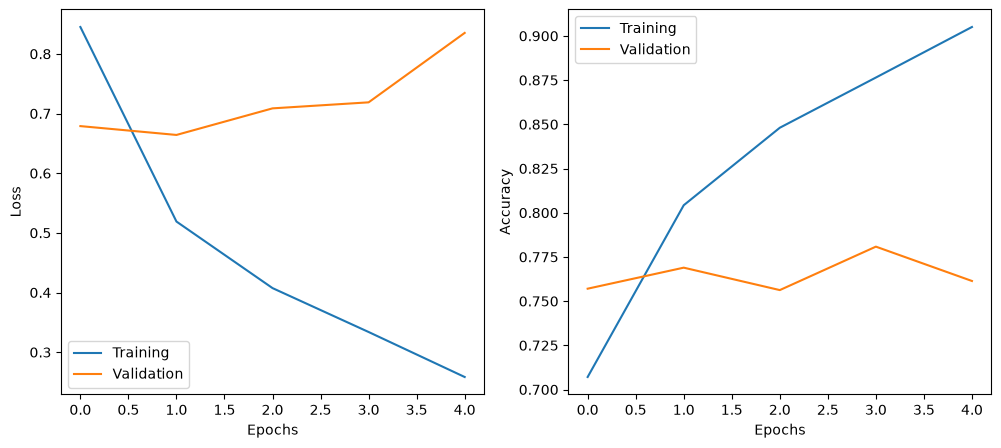

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(["Training", "Validation"])

plt.subplot(1,2,2)
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(["Training", "Validation"])

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


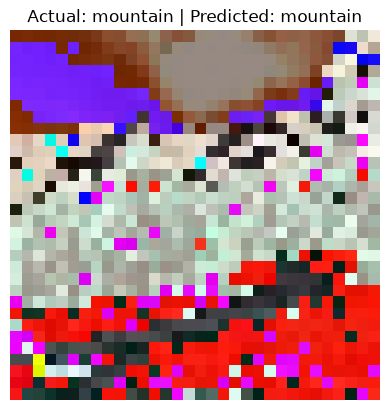

In [25]:
x,y = next(val)
p = model.predict(x)
i = 0
plt.imshow(x[i].astype("uint8"))
plt.title(f"Actual: {list(val.class_indices)[np.argmax(y[i])]} | Predicted: {list(val.class_indices)[np.argmax(p[i])]}")
plt.axis("off")
plt.show()